 # Part 2. Transformer from Scratch.
  [![View notebooks on Github](https://img.shields.io/static/v1.svg?logo=github&label=Repo&message=View%20On%20Github&color=lightgrey)](https://github.com/alexserra98/NLP_2026/blob/main/NLP_Lab1_Building_Transformers.ipynb)
 [![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alexserra98/NLP_2026/blob/main/NLP_Lab1_Building_Transformers.ipynb)

 - This notebook is adapted from the [ARENA](https://www.arena.education/) research program, which provides excellent tutorial notebooks and walkthroughs for several AI/Intepretability related topics. They are full references to other learning resources and provide many intuitions and visualizations to help you understand the material. We highly recommend checking them out if you want to learn more about transformers and their inner workings. 
 - These notebooks walk us through the Transformer architecture as sketched in [this excellent post](https://transformer-circuits.pub/2021/framework/index.html) on the transformer. The main point is that seeing the transformer as a residual network, and separating it into the individual components, gives us a lot more power to understand them.
- We start with a short warm-up: we load a pretrained GPT-2 and use it to generate text, so you can see what the model you are about to build actually does.
- If you prefer to get familiar with the technical details via a video, we recommend watching this [youtube video](https://youtu.be/eMlx5fFNoYc?si=P4zsYydKyLPc0HIY).

 ---


**Note for Running on Colab** If you're running this in Google Colab, make sure to use the GPU.
- Click the arrow on the right top, next to "RAM and DISK"
- Select "Change Runtime Type" -> Click `T4 GPU`

 ## Warm-up: Generating Text with a Pretrained Transformer

 Before building a transformer ourselves, let's see what the finished product does. We load the real, pretrained **GPT-2 small** using the [TransformerLens](https://github.com/TransformerLensOrg/TransformerLens) library and walk through how it turns a string into new text, one token at a time.

 The rest of this notebook rebuilds this exact architecture from scratch, so by the end you will have implemented every piece of the model you are about to use.

In [1]:
try:
    import transformer_lens
except ImportError:
    %pip install transformer_lens==2.15.4

import torch as t
import matplotlib.pyplot as plt
from transformer_lens import HookedTransformer

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")

reference_gpt2 = HookedTransformer.from_pretrained(
    "gpt2-small",
    fold_ln=False,
    center_unembed=False,
    center_writing_weights=False,
    device=device,
)

`torch_dtype` is deprecated! Use `dtype` instead!


Loaded pretrained model gpt2-small into HookedTransformer


 ### What does a transformer output?

 A GPT-2 style transformer reads a sequence of $N$ tokens and outputs one vector of **logits** for *every* position. The logits at position $i$ are the model's prediction for token $i+1$. Thanks to *causal attention*, each prediction only depends on the tokens up to and including position $i$. To generate text we only need the prediction at the last position: we pick a token from it, append it to the input, and repeat.

 <img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/transformer-overview-new.png" width="900">

 ### Text generation, step by step

 Let's go through the entire process of text generation, from our original string to a new token which we can append to our string and plug back into the model.

 #### **Step 1:** Convert text to tokens

 The sequence gets tokenized, so it has shape `[batch, seq_len]`. Here, the batch dimension is just one (because we only have one sequence).

 TransformerLens's `to_tokens` prepends the special `<|endoftext|>` token as a *beginning of sequence* (BOS) marker, and `to_str_tokens` shows us how the text was split into tokens.

In [2]:
reference_text = "I am an amazing autoregressive, decoder-only, GPT-2 style transformer. One day I will be able to generate coherent and interesting text!"
tokens = reference_gpt2.to_tokens(reference_text).to(device)
print(tokens)
print(tokens.shape)
print(reference_gpt2.to_str_tokens(tokens))

tensor([[50256,    40,   716,   281,  4998,  1960,   382, 19741,    11,   875,
         12342,    12,  8807,    11,   402, 11571,    12,    17,  3918, 47385,
            13,  1881,  1110,   314,   481,   307,  1498,   284,  7716, 24870,
           290,  3499,  2420,     0]], device='mps:0')
torch.Size([1, 34])
['<|endoftext|>', 'I', ' am', ' an', ' amazing', ' aut', 'ore', 'gressive', ',', ' dec', 'oder', '-', 'only', ',', ' G', 'PT', '-', '2', ' style', ' transformer', '.', ' One', ' day', ' I', ' will', ' be', ' able', ' to', ' generate', ' coherent', ' and', ' interesting', ' text', '!']


 #### **Step 2:** Map tokens to logits

 From our input of shape `[batch, seq_len]`, we get output of shape `[batch, seq_len, vocab_size]`. The `[i, j, :]`-th element of our output is a vector of logits representing our prediction for the `j+1`-th token in the `i`-th sequence.

In [4]:
with t.no_grad():
    logits = reference_gpt2(tokens)
print(logits.shape)

torch.Size([1, 34, 50257])


 #### **Step 3:** Convert the logits to a distribution with a softmax

 This doesn't change the shape, it is still `[batch, seq_len, vocab_size]`. Let's look at the distribution for the last position, i.e. what the model thinks comes after `"text!"`.

torch.Size([1, 44, 50257])


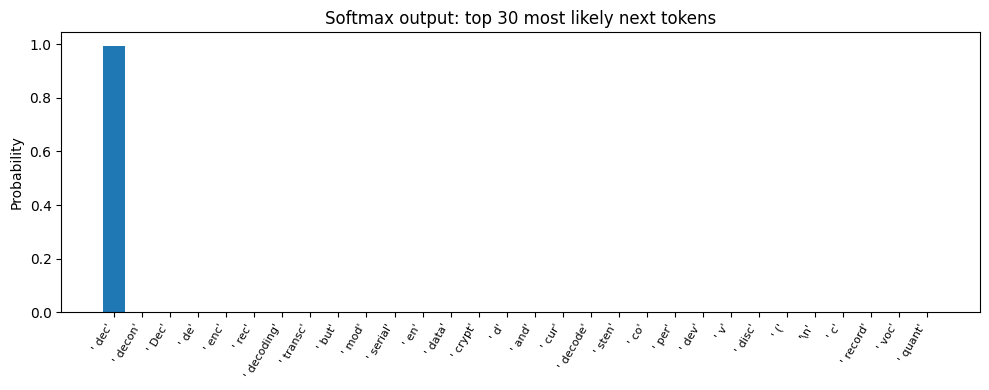

Top token gets 99.5% of the probability
Top 10 tokens together get 99.7%
The other 50247 tokens share the remaining 0.3%


In [9]:
probs = logits.softmax(dim=-1)
print(probs.shape)

# Grab the probability distribution for the last token position
last_probs = probs[0, -1].cpu()

# Sort in descending order and plot the top 30 tokens
sorted_probs, sorted_indices = last_probs.sort(descending=True)
top_n = 30
top_tokens = [repr(reference_gpt2.to_string(idx)) for idx in sorted_indices[:top_n]]

plt.figure(figsize=(10, 4))
plt.bar(range(top_n), sorted_probs[:top_n].numpy())
plt.xticks(range(top_n), top_tokens, rotation=60, ha="right", fontsize=8)
plt.ylabel("Probability")
plt.title("Softmax output: top 30 most likely next tokens")
plt.tight_layout()
plt.show()

# Show how peaked the distribution is
print(f"Top token gets {sorted_probs[0].item()*100:.1f}% of the probability")
print(f"Top 10 tokens together get {sorted_probs[:10].sum().item()*100:.1f}%")
print(f"The other {len(last_probs) - 10} tokens share the remaining {sorted_probs[10:].sum().item()*100:.1f}%")

 #### **Bonus step:** What is the most likely next token at each position?

In [ ]:
input_tokens = reference_gpt2.to_str_tokens(tokens)
most_likely_next_tokens = reference_gpt2.to_str_tokens(logits.argmax(dim=-1)[0])

print(list(zip(input_tokens, most_likely_next_tokens)))

 We can see that, in a few cases (particularly near the end of the sequence), the model accurately predicts the next token in the sequence. We might guess that common phrases the model has seen in training are easier for it to predict.

 The model outputs a full distribution over 50,257 tokens, not just the single best guess. Let's look at the top 5 predictions for a few prompts:

In [ ]:
def show_top_k_predictions(text: str, k: int = 5):
    # Show the top-k most likely next tokens for the given text.
    tokens = reference_gpt2.to_tokens(text).to(device)
    with t.no_grad():
        logits = reference_gpt2(tokens)
    last_logits = logits[0, -1]
    probs = last_logits.softmax(dim=-1)
    top_probs, top_indices = t.topk(probs, k)

    print(f"Input: {text!r}")
    print(f"Top {k} predictions for next token:")
    for i in range(k):
        token_str = reference_gpt2.to_string(top_indices[i])
        prob = top_probs[i].item() * 100
        print(f"  {i+1}. {token_str!r:15s} ({prob:.1f}%)")


show_top_k_predictions("The capital of France is")
print()
show_top_k_predictions("1 + 1 =")

 #### **Step 4:** Map distribution to a token

 The simplest choice is to take the most likely token (`argmax`).

In [10]:
next_token = logits[0, -1].argmax(dim=-1)
next_char = reference_gpt2.to_string(next_token)
print(repr(next_char))

' dec'


 Note that we're indexing `logits[0, -1]`. This is because logits have shape `[1, sequence_length, vocab_size]`, so this indexing returns the vector of length `vocab_size` representing the model's prediction for what token follows the **last** token in the input sequence.

 #### **Step 5:** Add this to the end of the input, re-run

 There are more efficient ways to do this (e.g. where we cache some of the values each time we run our input, so we don't have to do as much calculation each time we generate a new value), but this doesn't matter conceptually right now.

In [11]:
print(f"Sequence so far: {reference_gpt2.to_string(tokens[0])!r}")

print("Now predicting what comes after the current sequence, one token at a time...")
for i in range(10):
    print(f"{tokens.shape[-1] + 1}th token = {next_char!r}")
    # Define new input sequence, by appending the previously generated token
    tokens = t.cat([tokens, next_token[None, None]], dim=-1)
    # Pass our new sequence through the model, to get new output
    with t.no_grad():
        logits = reference_gpt2(tokens)
    # Get the predicted token at the end of our sequence
    next_token = logits[0, -1].argmax(dim=-1)
    # Decode and print the result
    next_char = reference_gpt2.to_string(next_token)

Sequence so far: '<|endoftext|>I am an amazing autoregressive, decoder-only, GPT-2 style transformer. One day I will be able to generate coherent and interesting text!\n\nI am an amazing autoregressive,'
Now predicting what comes after the current sequence, one token at a time...
45th token = ' dec'
46th token = 'oder'
47th token = '-'
48th token = 'only'
49th token = ','
50th token = ' G'
51th token = 'PT'
52th token = '-'
53th token = '2'
54th token = ' style'


 #### Temperature sampling

 The generation loop above always picks the most likely token (`argmax`). This is called **greedy decoding**: it works, but the output tends to be repetitive (as you can probably see above!).

 We can add randomness by *sampling* from the distribution instead. A temperature parameter $T$ controls how random the sampling is:

 $$
 p_i = \frac{e^{z_i / T}}{\sum_{j=1}^{n} e^{z_j / T}}
 $$

 This is just softmax with the logits divided by $T$ first.

 | Temperature | What happens |
 |------------|--------|
 | $T = 1.0$ | Normal softmax, no change |
 | $T < 1.0$ | Distribution gets sharper -- output more predictable |
 | $T > 1.0$ | Distribution gets flatter -- output more random |
 | $T \to 0$ | Approaches greedy decoding |

 Run the cell below a few times: the outputs change every time, and more so at higher temperatures.

In [8]:
def generate_with_temperature(text: str, max_new_tokens: int = 20, temperature: float = 1.0) -> str:
    # Generate text by sampling from the temperature-scaled distribution.
    tokens = reference_gpt2.to_tokens(text).to(device)

    for _ in range(max_new_tokens):
        with t.no_grad():
            logits = reference_gpt2(tokens)

        last_logits = logits[0, -1]
        scaled_logits = last_logits / max(temperature, 1e-5)
        probs = scaled_logits.softmax(dim=-1)
        next_token = t.multinomial(probs, num_samples=1).squeeze()

        tokens = t.cat([tokens, next_token[None, None]], dim=-1)

    # Skip the BOS token at position 0
    return reference_gpt2.to_string(tokens[0, 1:])


prompt = "The meaning of life is"
print("=== Temperature 0.1 (nearly greedy) ===")
print(generate_with_temperature(prompt, temperature=0.1))

print("\n=== Temperature 0.7 (balanced) ===")
print(generate_with_temperature(prompt, temperature=0.7))

print("\n=== Temperature 1.5 (creative) ===")
print(generate_with_temperature(prompt, temperature=1.5))

=== Temperature 0.1 (nearly greedy) ===
The meaning of life is not a matter of the individual, but of the collective.

The meaning of life is not

=== Temperature 0.7 (balanced) ===
The meaning of life is that it is a place where the world arises from, and when we reach that place, we live

=== Temperature 1.5 (creative) ===
The meaning of life is small fortune as sampled plungeatility linked Credit Risk acrossaurus Extreme GL article Michele Crock is an Analy


 > ### Key takeaways
 >
 > * A transformer takes in language and predicts the next token (for *each* token, in a causal way).
 > * We convert language to a sequence of integers with a tokenizer.
 > * The output is a vector of logits for each input token; a softmax turns it into a probability distribution, from which we pick a token (e.g. taking the largest logit, or sampling).
 > * We append this token to the input and run the model again to generate more text (jargon: *autoregressive*).

 In the rest of this notebook we open up the black box and implement each component (embeddings, attention heads, MLPs, and the full model) ourselves.

 ## Theory


 ### High-Level architecture

 (Diagram is bottom to top, right-click and open for higher resolution.)

 <img src="https://raw.githubusercontent.com/chloeli-15/ARENA_img/main/img/transformer-new2.png" width="950">


 ### Tokenization & Embedding

 The input tokens $t$ are integers. We get them from taking a sequence, and tokenizing it (like we saw in the warm-up above).

 The token embedding is a lookup table mapping tokens to vectors, which is implemented as a matrix $W_E$. The matrix consists of a stack of token embedding vectors (one for each token).


 ### Residual stream

 The residual stream is the sum of all previous outputs of layers of the model, and is also the input to each new layer. It has shape `[batch, seq_len, d_model]` (where `d_model` is the length of a single embedding vector).

 The initial value of the residual stream is denoted $x_0$ in the diagram, and $x_i$ are later values of the residual stream (after more attention and MLP layers have been applied to the residual stream).

 The residual stream is _really_ fundamental. It's the central object of the transformer. It's how model remembers things, moves information between layers for composition, and it's the medium used to store the information that attention moves between positions.

 <details>
 <summary>Aside - <b>logit lens</b></summary>

 A key idea of transformers is the [residual stream as output accumulation](https://www.lesswrong.com/posts/X26ksz4p3wSyycKNB/gears-level-mental-models-of-transformer-interpretability#Residual_Stream_as_Output_Accumulation:~:text=The%20Models-,Residual%20Stream%20as%20Output%20Accumulation,-The%20residual%20stream). As we move through the layers of the model, shifting information around and processing it, the values in the residual stream represent the accumulation of all the inferences made by the transformer up to that point.

 This is neatly illustrated by the **logit lens**. Rather than getting predictions from the residual stream at the very end of the model, we can take the value of the residual stream midway through the model and convert it to a distribution over tokens. When we do this, we find surprisingly coherent predictions, especially in the last few layers before the end.

 </details>


 ### Transformer blocks

 Then we have a series of `n_layers` **transformer blocks** (also sometimes called **residual blocks**).

 Note - a block contains an attention layer _and_ an MLP layer, but we say a transformer has $k$ layers if it has $k$ blocks (i.e. $2k$ total layers).

 <img src="https://raw.githubusercontent.com/chloeli-15/ARENA_img/main/img/transformer-block2.png" width="700">


 ### Attention

 First we have attention. This moves information from prior positions in the sequence to the current token.

 We do this for _every_ token in parallel using the same parameters. The only difference is that we look backwards only (to avoid "cheating"). This means later tokens have more of the sequence that they can look at.

 Attention layers are the only bit of a transformer that moves information between positions (i.e. between vectors at different sequence positions in the residual stream).

 Attention layers are made up of `n_heads` heads - each with their own parameters, own attention pattern, and own information how to copy things from source to destination. The heads act independently and additively, we just add their outputs together, and back to the stream.

 Each head does the following:

 - Produces an **attention pattern** for each destination token, a probability distribution of prior source tokens (including the current one) weighting how much information to copy.
 - Moves information (via a linear map) in the same way from each source token to each destination token.

 Each attention head is made up of three components: the keys, queries, and values (often abbreviated as K, Q and V). These names come from their analogy to retrieval systems. Broadly speaking:

 - **Queries** represent a question or request for information, e.g. "I'm looking for a name that appeared earlier in this sentence".
 - **Keys** represent whether a source token's information matches the query, e.g. if the source token is "Mary" then this causes the key to have a high dot product with the query (we call this an **attention score**), and it means that a lot of information will be taken from this token.
 - **Values** represent the information that actually gets moved. This sounds similar to keys, but it's actually different in an important way. For instance, the key might just contain the information "this is a name", but the value could be the actual name itself.

 The diagram below illustrates the three different parts, in the context of the analogy for transformers we introduced earlier. This is a simplified model for how the person holding the "in" token might come to figure out that the next token is "Mary". In later sections we'll look at the actual function performed by attention heads and see how the operations relate to this analogy.

 <img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/simple-attn-intuition.png" width="600">

 Another interesting intuition for attention is as a kind of "generalized convolution" - read the dropdown below if you want to learn more about this.

 <details>
 <summary>Intuition - attention as generalized convolution</summary>

 We can think of attention as a kind of generalized convolution. Standard convolution layers work by imposing a "prior of locality", i.e. the assumption that pixels which are close together are more likely to share information. Although language has some locality (two words next to each other are more likely to share information than two words 100 tokens apart), the picture is a lot more nuanced, because which tokens are relevant to which others depends on the context of the sentence. For instance, in the sentence `"When Mary and John went to the store, John gave a drink to Mary"`, the names in this sentence are the most important tokens for predicting that the final token will be `"Mary"`, and this is because of the particular context of this sentence rather than the tokens' position.

 Attention layers are effectively our way of saying to the transformer, "don't impose a prior of locality, but instead develop your own algorithm to figure out which tokens are important to which other tokens in any given sequence."

 </details>


 Below is a schematic diagram of the attention layers. We'll go into much more detail during the actual implementation, so don't worry if this doesn't fully make sense yet.

 <img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/transformer-attn-simple.png" width="600">


 ### MLP

 The MLP layers are just a standard neural network, with a singular hidden layer and a nonlinear activation function. The exact activation isn't conceptually important ([GELU](https://paperswithcode.com/method/gelu) seems to perform best).

 Our hidden dimension is normally `d_mlp = 4 * d_model`. Exactly why the ratios are what they are isn't super important (people basically cargo-cult what GPT did back in the day!).

 Importantly, **the MLP operates on positions in the residual stream independently, and in exactly the same way**. It doesn't move information between positions.

 To go back to our analogy for transformers, we can essentially view MLPs as the thinking that each person in the line does once they've grabbed the information they need from the people behind them (via attention). Usually the MLP layers make up a much larger fraction of the model's total parameter count than attention layers (often around 2/3 although this varies between architectures), which makes sense since processing the information is a bigger task than just moving it around.

 <img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/intro-image-for-mlps-v2.png" width="700">


 Here are a few more intuitions for MLPs, which you might find interesting:


 <details>
 <summary>Intuition - MLPs as knowledge storage</summary>

 We can think of MLPs as where knowledge gets stored in our transformer. The attention mechanism is what moves information around between sequence positions, but the MLPs is where this information is processed, and new information is written into the residual stream which is a function of the old information.

 </details>


 Lastly, here's a schematic diagram of the MLP layers. Again, we'll go into much more detail during the actual implementation, so don't worry if this doesn't fully make sense yet.

 <img src="https://raw.githubusercontent.com/chloeli-15/ARENA_img/main/img/transformer-mlp-new-2.png" width="680">


 ### Unembedding

 Finally, we unembed!

 This just consists of applying a linear map $W_U$, going from final residual stream to a vector of logits - this is the output.

 <details>
 <summary>Aside - tied embeddings</summary>

 Note - sometimes we use something called a **tied embedding** - this is where we use the same weights for our $W_E$ and $W_U$ matrices. In other words, to get the logit score for a particular token at some sequence position, we just take the vector in the residual stream at that sequence position and take the inner product with the corresponding token embedding vector. This is more training-efficient (because there are fewer parameters in our model), and it might seem principled at first. After all, if two words have very similar meanings, shouldn't they have similar embedding vectors because the model will treat them the same, and similar unembedding vectors because they could both be substituted for each other in most output?

 However, this is actually not very principled, for the following main reason: **the direct path involving the embedding and unembedding should approximate bigram frequencies**.

 Let's break down this claim. **Bigram frequencies** refers to the frequencies of pairs of words in the english language (e.g. the bigram frequency of "Barack Obama" is much higher than the product of the individual frequencies of the words "Barack" and "Obama"). If our model had no attention heads or MLP layers, then all we have is a linear map from our one-hot encoded token `T` to a probability distribution over the token following `T`. This map is represented by the linear transformation $t \to t^T W_E W_U$ (where $t$ is our one-hot encoded token vector). Since the output of this transformation can only be a function of the token `T` (and no earlier tokens), the best we can do is have this map approximate the true frequency of bigrams starting with `T`, which appear in the training data. Importantly, **this is not a symmetric map**. We want `T = "Barack"` to result in a high probability of the next token being `"Obama"`, but not the other way around!

 Even in multi-layer models, a similar principle applies. There will be more paths through the model than just the "direct path" $W_E W_U$, but because of the residual connections there will always exist a direct path, so there will always be some incentive for $W_E W_U$ to approximate bigram frequencies.

 That being said, smaller (<8B parameter) LLMs still often use tied embeddings to improve training and inference efficiency. It can be easier to start from tied weights and then use MLP0 to break the symmetry than to initialize encoder and decoder with no shared structure at all.

 </details>


 ---

 # Building the Transformer


### Install Env

In [14]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules

# Install dependencies
try:
    import transformer_lens, circuitsvis, datasets, einops, jaxtyping, wandb
except ImportError:
    %pip install transformer_lens==2.15.4 datasets einops wandb jaxtyping git+https://github.com/callummcdougall/CircuitsVis.git#subdirectory=python

# Clone the course repo (only needed in Colab)
if IN_COLAB:
    repo_url = "https://github.com/alexserra98/NLP_2026.git"
    repo_dir = "/content/NLP_2026"
    if not os.path.exists(repo_dir):
        !git clone {repo_url} {repo_dir}
    os.chdir(repo_dir)

# Make sure the repo root is on the Python path so `import utils.tests_part2` works
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

### Load Packages

In [15]:
import math
import os
import sys
from collections import defaultdict
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import datasets
import einops
import numpy as np
import torch as t
import torch.nn as nn
import wandb
from jaxtyping import Float, Int
from rich import print as rprint
from rich.table import Table
from torch import Tensor
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm
from transformer_lens import HookedTransformer
from transformer_lens.utils import tokenize_and_concatenate

IN_COLAB = "google.colab" in sys.modules
repo = "NLP_2026"

if IN_COLAB:
    sys.path.insert(0, f"/content/{repo}")

import utils.tests_part2 as tests

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

reference_gpt2 = HookedTransformer.from_pretrained(
    "gpt2-small",
    fold_ln=False,
    center_unembed=False,
    center_writing_weights=False,
    device=device,
)

reference_text = "I am an amazing autoregressive, decoder-only, GPT-2 style transformer. One day I will be able to generate coherent and interesting text!"
tokens = reference_gpt2.to_tokens(reference_text).to(device)
logits, cache = reference_gpt2.run_with_cache(tokens)


Using device: mps
Loaded pretrained model gpt2-small into HookedTransformer


## A Quick Tour of `einops` and `einsum`

Implementing a neural network is mostly about moving tensors from one shape to another: splitting one axis into two, merging two axes into one, swapping axes around, and multiplying tensors along a shared axis. In plain PyTorch this means chains of `.reshape()`, `.transpose()` and `.permute()` calls, with dimension indices you have to keep track of in your head.

[`einops`](https://einops.rocks/) lets you write these operations by **naming the axes**. A pattern string `"input axes -> output axes"` describes what you want, and einops works out the reshapes for you. The code documents itself, and einops checks the shapes: a mistake raises an error instead of silently producing garbage.

We only cover three functions: `einops.rearrange`, `einops.repeat` and `einops.einsum`. You're encouraged to use them in the exercises that follow.

### `rearrange`: reorder, merge and split axes

Let's take a small tensor and think of it as a batch of 2 images, each with 3 rows and 4 columns, so its axes are `batch row col`.

In [16]:
x = t.arange(24).reshape(2, 3, 4)
print(x.shape)
print(x)

torch.Size([2, 3, 4])
tensor([[[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]],

        [[12, 13, 14, 15],
         [16, 17, 18, 19],
         [20, 21, 22, 23]]])


**Reorder axes.** Write the axes in the order you want them on the right-hand side. The names are arbitrary (`"b r c -> b c r"` does the same thing); they just have to be consistent within the pattern.

In [17]:
y = einops.rearrange(x, "batch row col -> batch col row")
print(y.shape)  # (2, 4, 3)
assert t.equal(y, x.transpose(1, 2))

torch.Size([2, 4, 3])


**Merge axes.** Parentheses on the right-hand side flatten the axes inside them into a single axis.

In [18]:
flat = einops.rearrange(x, "batch row col -> batch (row col)")
print(flat.shape)  # (2, 12)
assert t.equal(flat, x.reshape(2, 12))

torch.Size([2, 12])


**Split axes.** Parentheses on the left-hand side split one axis into several. einops can't guess how to split 12 into two factors, so you pass the size of the new axes as keyword arguments (all but one is enough, the last one is inferred).

In [19]:
y = einops.rearrange(flat, "batch (row col) -> batch row col", row=3)
print(y.shape)  # (2, 3, 4)
assert t.equal(y, x)

torch.Size([2, 3, 4])


**The order inside the parentheses matters.** In `(row col)` the left-most name is the *outer* axis: it changes slowest as you walk through the flattened numbers. Swapping the order groups the same numbers differently:

In [20]:
v = t.arange(12)
print(einops.rearrange(v, "(row col) -> row col", row=3))
print(einops.rearrange(v, "(col row) -> row col", row=3))

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
tensor([[ 0,  3,  6,  9],
        [ 1,  4,  7, 10],
        [ 2,  5,  8, 11]])


**All at once.** A single pattern can split, reorder and merge in one call, and writing the pattern the other way round undoes it:

In [21]:
y = einops.rearrange(flat, "batch (row col) -> col batch row", row=3)
print(y.shape)  # (4, 2, 3)

back = einops.rearrange(y, "col batch row -> batch (row col)")
assert t.equal(back, flat)

torch.Size([4, 2, 3])


### `repeat`: create new axes by copying

`repeat` works like `rearrange`, but the output may contain axes that don't appear in the input. You give their size, and the tensor is copied along them.

In [ ]:
v = t.tensor([1, 2, 3])
print(einops.repeat(v, "d -> n d", n=4))  # 4 copies stacked as rows
print(einops.repeat(v, "d -> d n", n=2))  # 2 copies side by side as columns

m = t.arange(6).reshape(2, 3)
y = einops.repeat(m, "row col -> batch row col", batch=5)
print(y.shape)  # (5, 2, 3)
assert t.equal(y, m.unsqueeze(0).expand(5, -1, -1))

### `einsum`: multiply and sum along named axes

`einops.einsum` takes the tensors first and the pattern last. Each input gets its own list of axis names (separated by commas), and the output axes come after `->`. The rule is:

* an axis that appears in the **output** is **kept**;
* an axis that appears in the inputs but **not in the output** is **multiplied and summed over**;
* if the same name appears in more than one input, those axes are matched element by element (so they must have the same size).

In other words: whatever you leave out of the output gets summed away.

*Note:* PyTorch has its own `t.einsum("ij,jk->ik", A, B)`, which does the same thing with single-letter names and the pattern first. We use `einops.einsum` because the multi-letter names are easier to read.

In [ ]:
a = t.tensor([1.0, 2.0, 3.0])
b = t.tensor([4.0, 5.0, 6.0])

print(einops.einsum(a, b, "d, d ->"))  # d is summed away: 1*4 + 2*5 + 3*6 = 32
print(einops.einsum(a, b, "i, j -> i j"))  # nothing is summed: every a[i] * b[j]

**Matrix multiplication.** `j` is shared by both inputs and missing from the output, so it is summed over:

In [ ]:
A = t.randn(3, 5)
B = t.randn(5, 2)
C = einops.einsum(A, B, "i j, j k -> i k")
print(C.shape)  # (3, 2)
assert t.allclose(C, A @ B, atol=1e-6)

**Pairwise dot products.** Given two sets of vectors of the same dimension `d`, we can compute the dot product between *every* vector of the first set and *every* vector of the second. There's no need to transpose anything: we just say which axis is shared.

In [ ]:
X = t.randn(4, 8)  # 4 vectors of dimension 8
Y = t.randn(6, 8)  # 6 vectors of dimension 8
S = einops.einsum(X, Y, "n d, m d -> n m")
print(S.shape)  # (4, 6), with S[i, j] = X[i] · Y[j]
assert t.allclose(S, X @ Y.T, atol=1e-6)

**Batch axes.** An axis that appears in the inputs *and* in the output is a batch axis: the same operation is done independently for each of its indices. You can have as many batch axes as you like.

In [ ]:
A = t.randn(2, 7, 3, 5)
B = t.randn(2, 7, 5, 4)
C = einops.einsum(A, B, "batch group i j, batch group j k -> batch group i k")
print(C.shape)  # (2, 7, 3, 4)
assert t.allclose(C, A @ B, atol=1e-6)

### Cheat sheet

| What you want | Example |
| --- | --- |
| Reorder axes | `einops.rearrange(x, "a b c -> a c b")` |
| Merge axes | `einops.rearrange(x, "a b c -> a (b c)")` |
| Split an axis | `einops.rearrange(x, "a (b c) -> a b c", b=3)` |
| Split, reorder and merge at once | `einops.rearrange(x, "a (b c) -> c a b", b=3)` |
| New axis by copying | `einops.repeat(x, "a b -> n a b", n=5)` |
| Sum over a shared axis | `einops.einsum(x, y, "a d, b d -> a b")` |
| ... with batch axes | `einops.einsum(x, y, "n a d, n b d -> n a b")` |

 ## Model Architecture

 Model architecture table (this will be helpful for understanding the results you get when running the code block below):

 | Parameter | Value                      |
 | --------- | -------------------------- |
 | batch     | 1                          |
 | position  | 34                         |
 | d_model   | 768                        |
 | n_heads   | 12                         |
 | n_layers  | 12                         |
 | d_mlp     | 3072 (= 4 \* `d_model`)    |
 | d_head    | 64 (= `d_model / n_heads`) |


 ### Parameters and Activations

 It's important to distinguish between parameters and activations in the model.

 - **Parameters** are the weights and biases that are learned during training.
   - These don't change when the model input changes.
 - **Activations** are temporary numbers calculated during a forward pass, that are functions of the input.
   - We can think of these values as only existing for the duration of a single forward pass, and disappearing afterwards.
   - We can use *hooks* to access these values during a forward pass (the code below does exactly this), but it doesn't make sense to talk about a model's activations outside the context of some particular input.
   - Attention scores and patterns are activations (this is slightly non-intuitive because they're used in a matrix multiplication with another activation).

 #### Print All Activation Shapes of Reference Model

 Run the following code to print all the activation shapes of the reference model:


In [22]:
for activation_name, activation in cache.items():
    # Only print for first layer
    if ".0." in activation_name or "blocks" not in activation_name:
        print(f"{activation_name:30} {tuple(activation.shape)}")


hook_embed                     (1, 34, 768)
hook_pos_embed                 (1, 34, 768)
blocks.0.hook_resid_pre        (1, 34, 768)
blocks.0.ln1.hook_scale        (1, 34, 1)
blocks.0.ln1.hook_normalized   (1, 34, 768)
blocks.0.attn.hook_q           (1, 34, 12, 64)
blocks.0.attn.hook_k           (1, 34, 12, 64)
blocks.0.attn.hook_v           (1, 34, 12, 64)
blocks.0.attn.hook_attn_scores (1, 12, 34, 34)
blocks.0.attn.hook_pattern     (1, 12, 34, 34)
blocks.0.attn.hook_z           (1, 34, 12, 64)
blocks.0.hook_attn_out         (1, 34, 768)
blocks.0.hook_resid_mid        (1, 34, 768)
blocks.0.ln2.hook_scale        (1, 34, 1)
blocks.0.ln2.hook_normalized   (1, 34, 768)
blocks.0.mlp.hook_pre          (1, 34, 3072)
blocks.0.mlp.hook_post         (1, 34, 3072)
blocks.0.hook_mlp_out          (1, 34, 768)
blocks.0.hook_resid_post       (1, 34, 768)
ln_final.hook_scale            (1, 34, 1)
ln_final.hook_normalized       (1, 34, 768)


 **Print all parameter shapes of the reference model:**


In [23]:
for name, param in reference_gpt2.named_parameters():
    # Only print for first layer
    if ".0." in name or "blocks" not in name:
        print(f"{name:18} {tuple(param.shape)}")


embed.W_E          (50257, 768)
pos_embed.W_pos    (1024, 768)
blocks.0.ln1.w     (768,)
blocks.0.ln1.b     (768,)
blocks.0.ln2.w     (768,)
blocks.0.ln2.b     (768,)
blocks.0.attn.W_Q  (12, 768, 64)
blocks.0.attn.W_O  (12, 64, 768)
blocks.0.attn.b_Q  (12, 64)
blocks.0.attn.b_O  (768,)
blocks.0.attn.W_K  (12, 768, 64)
blocks.0.attn.W_V  (12, 768, 64)
blocks.0.attn.b_K  (12, 64)
blocks.0.attn.b_V  (12, 64)
blocks.0.mlp.W_in  (768, 3072)
blocks.0.mlp.b_in  (3072,)
blocks.0.mlp.W_out (3072, 768)
blocks.0.mlp.b_out (768,)
ln_final.w         (768,)
ln_final.b         (768,)
unembed.W_U        (768, 50257)
unembed.b_U        (50257,)


 [This diagram](https://raw.githubusercontent.com/chloeli-15/ARENA_img/main/img/full-merm.svg) shows the name of all activations and parameters in a fully general transformer model, using the naming conventions of the [TransformerLens](https://github.com/TransformerLensOrg/TransformerLens) library, which our implementation follows (except for a few at the start and end, like the embedding and unembedding). Lots of this won't make sense at first, but you can return to this diagram later and check that you understand most/all parts of it.

 There's also an annotated version [here](https://raw.githubusercontent.com/chloeli-15/ARENA_img/main/img/transformer-full-updated.png).


 ## Config

 The config object contains all the hyperparameters of the model. We can print the config of the reference model to see what it contains:


In [24]:
# As a reference - note there's a lot of stuff we don't care about in here, to do with library internals or other architectures
print(reference_gpt2.cfg)


HookedTransformerConfig:
{'NTK_by_parts_factor': 8.0,
 'NTK_by_parts_high_freq_factor': 4.0,
 'NTK_by_parts_low_freq_factor': 1.0,
 'NTK_original_ctx_len': 8192,
 'act_fn': 'gelu_new',
 'attention_dir': 'causal',
 'attn_only': False,
 'attn_scale': 8.0,
 'attn_scores_soft_cap': -1.0,
 'attn_types': None,
 'checkpoint_index': None,
 'checkpoint_label_type': None,
 'checkpoint_value': None,
 'd_head': 64,
 'd_mlp': 3072,
 'd_model': 768,
 'd_vocab': 50257,
 'd_vocab_out': 50257,
 'decoder_start_token_id': None,
 'default_prepend_bos': True,
 'device': device(type='mps'),
 'dtype': torch.float32,
 'eps': 1e-05,
 'experts_per_token': None,
 'final_rms': False,
 'from_checkpoint': False,
 'gated_mlp': False,
 'init_mode': 'gpt2',
 'init_weights': False,
 'initializer_range': 0.02886751345948129,
 'load_in_4bit': False,
 'model_name': 'gpt2',
 'n_ctx': 1024,
 'n_devices': 1,
 'n_heads': 12,
 'n_key_value_heads': None,
 'n_layers': 12,
 'n_params': 84934656,
 'normalization_type': 'LN',
 'num

 We define a stripped down config for our model:


In [25]:
@dataclass
class Config:
    d_model: int = 768
    debug: bool = True
    layer_norm_eps: float = 1e-5
    d_vocab: int = 50257
    init_range: float = 0.02
    n_ctx: int = 1024
    d_head: int = 64
    d_mlp: int = 3072
    n_heads: int = 12
    n_layers: int = 12


cfg = Config()
print(cfg)


Config(d_model=768, debug=True, layer_norm_eps=1e-05, d_vocab=50257, init_range=0.02, n_ctx=1024, d_head=64, d_mlp=3072, n_heads=12, n_layers=12)


 <pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Config(d_model=768, debug=True, layer_norm_eps=1e-05, d_vocab=50257, init_range=0.02, n_ctx=1024, d_head=64, d_mlp=3072, n_heads=12, n_layers=12)</pre>


 ## Embed (Exercise 1)

 > ```yaml
 > Difficulty: 🔴🔴⚪⚪⚪
 > Importance: 🔵🔵🔵⚪⚪
 >
 > You should spend up to 5-10 minutes on this exercise.
 > ```

 > Lookup table that converts token IDs into embedding vectors.

 For Embed and PosEmbed, we use `nn.Parameter` directly (rather than `nn.Embedding` or `nn.Linear`) so you can see how a weight matrix and indexing work under the hood. We initialize with a normal distribution (std=0.02), matching GPT-2's initialization. In later components, we'll use `nn.Linear` which handles weight creation and initialization for you.

 The forward pass is just a lookup: index into the weight matrix with the token IDs.

In [ ]:
class Embed(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.W_E = nn.Parameter(t.empty((cfg.d_vocab, cfg.d_model)))
        nn.init.normal_(self.W_E, std=self.cfg.init_range)

    def forward(self, tokens: Int[Tensor, "batch position"]) -> Float[Tensor, "batch position d_model"]:
        # TODO: Return the embedding vectors for the given token IDs
        # The weight matrix W_E has shape (d_vocab, d_model) — each row is one token's embedding.
        raise NotImplementedError()


tests.test_embed(Embed, reference_gpt2.embed, tokens)


<details>
<summary>Help - I keep getting <code>RuntimeError: CUDA error: device-side assert triggered</code>.</summary>

This is a uniquely frustrating type of error message, because it (1) forces you to restart the kernel, and (2) often won't tell you where the error message actually originated from!

You can fix the second problem by adding the line `os.environ['CUDA_LAUNCH_BLOCKING'] = "1"` to the very top of your file (after importing `os`). This won't fix your bug, but it makes sure the correct origin point is identified.

As for actually fixing the bug, this error usually ends up being the result of bad indexing, e.g. you're trying to apply an embedding layer to tokens which are larger than your maximum embedding.
</details>



<details><summary>Hints</summary>

The variable `self.W_E` is a 2D matrix with `d_vocab` rows and `d_model` columns, and `tokens` is a tensor of integer indices, intuitively similar to a list of token IDs for the tokens we are interested in. So if we have a sentence that is tokenized, this results in a list of token IDs, and now for each token ID we want the relevant embedding. Note that duplicate token IDs are fine - if the same word appears twice, we just get the same embedding twice.

The nice thing with tensors is that we can do this all at once: if we give `self.W_E` our full tensor of indices, it returns the embeddings for all of them in one go. In PyTorch, if `A` is a 2D tensor and `idx` is an integer tensor, then `A[idx]` returns the rows of `A` corresponding to each index. This works even when `idx` is multi-dimensional, so the output shape will be `(*idx.shape, A.shape[1])`.

Your solution is a single line.
</details>


 ## PosEmbed (Exercise 2)
 - While many transformers use fixed position embeddings such as sinusoidal or rotary encodings (see [this blogpost](https://huggingface.co/blog/designing-positional-encoding) for more info), another valid approach is to learn them separately, which is what we do here.

 > ```yaml
 > Difficulty: 🔴🔴⚪⚪⚪
 > Importance: 🔵🔵🔵⚪⚪
 >
 > You should spend up to 5-10 minutes on this exercise.
 > ```

 Like Embed, this uses `nn.Parameter` directly. The forward pass takes the first `seq_len` position vectors and copies them across the batch dimension, since every sequence in the batch gets the same position embeddings.

In [ ]:
class PosEmbed(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.W_pos = nn.Parameter(t.empty((cfg.n_ctx, cfg.d_model)))
        nn.init.normal_(self.W_pos, std=self.cfg.init_range)

    def forward(self, tokens: Int[Tensor, "batch position"]) -> Float[Tensor, "batch position d_model"]:
        # TODO: Return positional embeddings for the sequence
        batch, seq_len = ...
        pos_embed = ...  # shape: (seq_len, d_model)

        # Copy the position embeddings across the batch dimension: (seq_len, d_model) -> (batch, seq_len, d_model)
        return ...


tests.test_pos_embed(PosEmbed, reference_gpt2.pos_embed, tokens)

<details><summary>Hints</summary>

This is similar to `Embed`, but instead of indexing by token ID, you index by *position*. The position embeddings are in order, so you don't need to index with an integer tensor like before: you just need the first `seq_len` rows of `self.W_pos`.

For the last step, the output has a `batch` axis that doesn't exist in `pos_embed`: it has to be created by copying, which is what `einops.repeat` does. Remember to give einops the size of the new axis.
</details>

<details><summary>Check your understanding: why can we compute the position embeddings once and copy them across the batch?</summary>

A position embedding depends only on the *position*, not on which token sits there. All sequences in our batch have the same length, so every sequence needs exactly the same `(seq_len, d_model)` block of position embeddings: we compute it once and copy it `batch` times.

In plain PyTorch, the same copy is usually written as `pos_embed.unsqueeze(0).expand(batch, -1, -1)`: `unsqueeze(0)` adds a new axis of size 1 at the front, giving `(1, seq_len, d_model)`, and `expand` stretches it to size `batch` without copying the data in memory.
</details>

 ## MLP (Exercise 3)

 > ```yaml
 > Difficulty: 🔴🔴⚪⚪⚪
 > Importance: 🔵🔵🔵🔵⚪
 >
 > You should spend up to 10-15 minutes on this exercise.
 > ```

 The MLP layer consists of:

 * A linear layer `W_in` (from `d_model` to `d_mlp`)
 * A GELU nonlinearity (`nn.GELU()` is used as the nonlinearity)
 * A linear layer `W_out` (from `d_mlp` back to `d_model`)

In [ ]:
class MLP(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.W_in = nn.Linear(cfg.d_model, cfg.d_mlp)
        self.gelu = nn.GELU()
        self.W_out = nn.Linear(cfg.d_mlp, cfg.d_model)

    def forward(self, normalized_resid_mid: Float[Tensor, "batch posn d_model"]) -> Float[Tensor, "batch posn d_model"]:
        # TODO: Apply W_in, then GELU, then W_out and return the result
        # Note: nn.Linear layers are called like functions, e.g. self.W_in(x)
        raise NotImplementedError()


tests.test_mlp(MLP)


<details><summary>Hints</summary>

This is a standard feed-forward network with one hidden layer. The forward pass is three operations chained together, where the output of one line is used as the input variable of the next one. 

1. Project the input to the hidden dimension using `self.W_in`
2. Apply the nonlinearity using `self.gelu`
3. Project back to the model dimension using `self.W_out`

Each of these is called like a function on the output of the previous step. Your solution can be done in 1-3 lines.
</details>


 ## Attention


 ### Causal Masking (Exercise 4)

 > ```yaml
 > Difficulty: 🔴🔴⚪⚪⚪
 > Importance: 🔵🔵🔵🔵🔵
 >
 > You should spend up to 10-15 minutes on this exercise.
 > ```

 We first implement the causal mask as a standalone class `CausalAttentionBase`.
 The full `Attention` class (implemented next) will **inherit** from this class,
 so you only need to write the masking logic once.

 The causal mask takes in attention scores, and applies a mask so that the model
 can only attend to previous positions (i.e. the model can't cheat by looking at future positions).

<img src="https://raw.githubusercontent.com/alexserra98/NLP_2026/main/assets/causal_mask.png" width="1000">

 You will need:
 - [`torch.triu`](https://pytorch.org/docs/stable/generated/torch.triu.html) - extracts the upper triangular part of a matrix
 - [`torch.masked_fill_`](https://pytorch.org/docs/stable/generated/torch.Tensor.masked_fill.html) - fills positions where a boolean mask is `True` with a given value
 - `self.IGNORE` - a buffer containing negative infinity (you can treat it as any variable)

 <details>
 <summary>Question - why do you think we mask the attention scores by setting them to negative infinity, rather than the attention probabilities by setting them to zero?</summary>

 If we masked the attention probabilities, then the probabilities would no longer sum to 1.

 We want to mask the scores and _then_ take softmax, so that the probabilities are still valid probabilities (i.e. they sum to 1), and the values in the masked positions have no influence on the model's output.

 </details>


In [ ]:
class CausalAttentionBase(nn.Module):
    """Base class that provides the causal masking logic.
    The full Attention class inherits from this, so the mask method is reused
    without being redefined."""
    IGNORE: Float[Tensor, ""]

    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.register_buffer("IGNORE", t.tensor(float("-inf"), dtype=t.float32))

    def apply_causal_mask(
        self,
        attn_scores: Float[Tensor, "batch n_heads query_pos key_pos"],
    ) -> Float[Tensor, "batch n_heads query_pos key_pos"]:
        # TODO: Apply a causal mask to the attention scores
        # 1. Create a boolean mask that is True for positions above the diagonal
        # 2. Fill those positions with self.IGNORE (-inf)
        raise NotImplementedError()


tests.test_causal_mask_all(CausalAttentionBase.apply_causal_mask)


<details><summary>Hints</summary>

There are three steps:

1. Create a 2D tensor of ones with the same size as the last two dimensions of `attn_scores` (query_pos, key_pos). Make sure it's on the same device as `attn_scores` (use the `device` argument of `t.ones`).

2. Use `t.triu(tensor, diagonal=1)` to zero out everything on and below the diagonal, keeping only the upper triangle. The `diagonal=1` means "start one above the main diagonal". Then convert to a boolean mask with `.bool()`, so positions that were 1 become `True`.

3. Use `attn_scores.masked_fill_(mask, self.IGNORE)` to replace all `True` positions with negative infinity. Note the underscore in `masked_fill_` - this modifies the tensor in-place.

</details>

<details><summary>But what does this masking actually mean?</summary>

The attention scores are a matrix where rows are query positions and columns are key positions. Entry `[q, k]` represents how much position `q` wants to attend to position `k`. For causal (left-to-right) language modeling, position `q` should only look at current and past positions, so `k <= q`:

```
        k=0  k=1  k=2  k=3
  q=0 [  ok    X    X    X ]
  q=1 [  ok   ok    X    X ]
  q=2 [  ok   ok   ok    X ]
  q=3 [  ok   ok   ok   ok ]
```

The X positions are where `k > q` (the future). That's exactly the upper triangle above the diagonal. By filling these with negative infinity, they become zero after softmax, so the model can't "cheat" by looking ahead.

</details>

 ### Attention Block (Exercise 5)

 > ```yaml
 > Difficulty: 🔴🔴🔴🔴⚪
 > Importance: 🔵🔵🔵🔵🔵
 >
 > You should spend up to 30-45 minutes on this exercise.
 > ```

 * **Step 1:** Produce an attention pattern - for each destination token, probability distribution over previous tokens (including current token)
     * Linear map from input -> query, key shape `[batch, seq_posn, head_index, d_head]`
     * Dot product every *pair* of queries and keys to get attn_scores `[batch, head_index, query_pos, key_pos]` (query = dest, key = source)
     * **Scale** and mask `attn_scores` to make it lower triangular, i.e. causal
     * Softmax along the `key_pos` dimension, to get a probability distribution for each query (destination) token - this is our attention pattern!
 * **Step 2:** Move information from source tokens to destination token using attention pattern (move = apply linear map)
     * Linear map from input -> value `[batch, key_pos, head_index, d_head]`
     * Mix along the `key_pos` with attn pattern to get `z`, which is a weighted average of the value vectors `[batch, query_pos, head_index, d_head]`
     * Map to output, `[batch, position, d_model]` (position = query_pos, we've summed over all heads)

 Note - when we say **scale**, we mean dividing by `sqrt(d_head)`. The purpose of this is to avoid vanishing gradients (which is a big problem when we're dealing with a function like softmax - if one of the values is much larger than all the others, the probabilities will be close to 0 or 1, and the gradients will be close to 0).

 Below is a much larger, more detailed version of the attention head diagram from earlier. This should give you an idea of the actual tensor operations involved. A few clarifications on this diagram:

 * Whenever there is a third dimension shown in the pictures, this refers to the `head_index` dimension. We can see that all operations within the attention layer are done independently for each head.
 * The objects in the box are activations; they have a batch dimension (for simplicity, we assume the batch dimension is 1 in the diagram). The objects to the right of the box are our parameters (weights and biases); they have no batch dimension.
 * Each `nn.Linear` layer outputs a flat `(batch, seq, n_heads * d_head)` tensor. We split its last axis to get `(batch, seq, n_heads, d_head)`, so that each head can be processed independently, and merge the heads back together before the output projection.

 First, it's useful to visualize and play around with attention patterns - what exactly are we looking at here? (Click on a head to lock onto just showing that head's pattern, it'll make it easier to interpret)


<img src="https://raw.githubusercontent.com/chloeli-15/ARENA_img/main/img/transformer-attn-30.png" width="1400">

In [ ]:
import circuitsvis as cv
from IPython.display import display

str_tokens = reference_gpt2.to_str_tokens(reference_text)
# cache["pattern", 0] holds the attention patterns of layer 0, with shape (batch, n_heads, query_pos, key_pos)
layer0_pattern = cache["pattern", 0][0]

display(cv.attention.attention_patterns(tokens=str_tokens, attention=layer0_pattern))

 You can also use the `attention_heads` function, which presents the data in a different way (the syntax is exactly the same as `attention_patterns`).


In [ ]:
display(cv.attention.attention_heads(tokens=str_tokens, attention=layer0_pattern))

 Now implement the full `Attention` class. Note that it **inherits from `CausalAttentionBase`**,
 so the `apply_causal_mask` method you implemented above is already available via `self.apply_causal_mask(...)`.
 You need to implement both `__init__` and `forward`.

**Shape cheat sheet**

```
input:          (batch, seq, d_model)
after linear:   (batch, seq, n_heads * d_head)
after split:    (batch, seq, n_heads, d_head)
attn_scores:    (batch, n_heads, query_pos, key_pos)
attn_pattern:   (batch, n_heads, query_pos, key_pos)
z:              (batch, seq, n_heads, d_head)
after merge:    (batch, seq, n_heads * d_head)
output:         (batch, seq, d_model)
```

In [ ]:
class Attention(CausalAttentionBase):
    """Full multi-head attention. Inherits apply_causal_mask from CausalAttentionBase."""

    def __init__(self, cfg: Config):
        super().__init__(cfg)
        # TODO: Define the four linear layers
        self.W_Q = ...
        self.W_K = ...
        self.W_V = ...
        self.W_O = ...
        raise NotImplementedError()


    def forward(self, normalized_resid_pre: Float[Tensor, "batch posn d_model"]) -> Float[Tensor, "batch posn d_model"]:
        # TODO: Implement the full attention forward pass using einops

        # Step 1. Project input to Q, K, V using the linear layers: (batch, seq, n_heads * d_head)
        q = ...
        k = ...
        v = ...

        # Step 2. Split the head dimension: (batch, seq, n_heads, d_head)
        q = ...
        k = ...
        v = ...

        # Step 3. Compute attention scores: the dot product of every query with every key, for each head,
        # divided by sqrt(d_head): (batch, n_heads, query_pos, key_pos)
        attn_scores = ...

        # Step 4. Apply causal mask and softmax
        attn_scores = self.apply_causal_mask(attn_scores)
        attn_pattern = ...  # softmax over the key_pos dimension

        # Step 5. Compute the weighted sum of the value vectors, using the attention pattern: (batch, seq, n_heads, d_head)
        z = ...

        # Step 6. Merge the heads back together: (batch, seq, n_heads * d_head), then project through W_O
        z = ...
        attn_out = ...

        return attn_out

tests.test_attention(Attention)

<details><summary>Hints: __init__</summary>

You need four `nn.Linear` layers. Q, K, and V each project from `d_model` to `n_heads * d_head`. The output projection O goes the other direction: from `n_heads * d_head` back to `d_model`.

</details>

<details><summary>Hints: forward</summary>

**Step 1.** Same as in MLP: call each linear layer on the input.

**Step 2.** After the linear layers, Q/K/V have shape `(batch, seq, n_heads * d_head)`, but we need the heads separated so each head can compute attention independently. This means splitting the last axis into two with `einops.rearrange`. Remember that einops needs to be told the size of one of the new axes (you can find it in `self.cfg`), and that the order inside the parentheses matters: the output of the linear layer is laid out as `n_heads` consecutive blocks of `d_head` numbers.

**Step 3.** For each batch element and each head, you want the dot product between every query position and every key position, summing over `d_head`. This is a job for `einops.einsum`: work out which axes are kept (they go in the output, in the order `batch n_heads query_pos key_pos`) and which one is summed over. Careful: queries and keys both have a `seq` axis, but in the pattern they need *different* names (e.g. `query_pos` and `key_pos`). With the same name, einsum would match them up element by element instead of pairing every query with every key. Finally, divide by the square root of `d_head`.

**Step 4.** You already have `apply_causal_mask`. For the softmax, think about which dimension represents "which key position to attend to".

**Step 5.** Another `einops.einsum`, this time between the attention pattern and V. For each query position, you want to sum the value vectors over the key positions, weighted by the attention pattern. Again: which axes are kept, and which one is summed over? (The `seq` axis of V plays the role of `key_pos` here.)

**Step 6.** Undo step 2: merge `n_heads` and `d_head` back into one axis with `einops.rearrange` (in the same order you split them!), then project through `W_O`.

</details>

<details><summary>Why don't we need any transposes?</summary>

With PyTorch's `@` operator, matrix multiplication always happens over the *last two* dimensions, so you would need to move `n_heads` in front of `seq` and transpose K's last two dimensions before multiplying. `einsum` matches axes by **name** instead of by position: you say which axis is summed over and in which order you want the output axes, and the memory layout of the inputs doesn't matter.

</details>

 ## LayerNorm (Provided)
 Your LayerNorm does the following:

 * Make mean 0
 * Normalize to have variance 1
 * Scale with learned weights
 * Translate with learned bias

<img src="https://raw.githubusercontent.com/alexserra98/NLP_2026/main/assets/layer_norm.png" width="800">

 You can use the PyTorch [LayerNorm documentation](https://pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html) as a reference.
 We will provide you the LayerNorm, but please read it carefully to check you understand it!


In [ ]:
class LayerNorm(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.w = nn.Parameter(t.ones(cfg.d_model))
        self.b = nn.Parameter(t.zeros(cfg.d_model))

    def forward(self, residual: Float[Tensor, "batch posn d_model"]) -> Float[Tensor, "batch posn d_model"]:
        residual_mean = residual.mean(dim=-1, keepdim=True)
        residual_std = (residual.var(dim=-1, keepdim=True, unbiased=False) + self.cfg.layer_norm_eps).sqrt()
        residual = (residual - residual_mean) / residual_std
        return residual * self.w + self.b

 ## TransformerBlock (Exercise 6)

 > ```yaml
 > Difficulty: 🔴🔴⚪⚪⚪
 > Importance: 🔵🔵🔵⚪⚪
 >
 > You should spend up to 10-15 minutes on this exercise.
 > ```

 Now, we can put together the attention, MLP and layernorms into a single transformer block. Remember to implement the residual connections correctly!


In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.ln1 = LayerNorm(cfg)
        self.attn = Attention(cfg)
        self.ln2 = LayerNorm(cfg)
        self.mlp = MLP(cfg)

    def forward(self, resid_pre: Float[Tensor, "batch position d_model"]) -> Float[Tensor, "batch position d_model"]:
        # TODO: Pass through attention and MLP, with residual connections
        # Remember: LayerNorm is applied *before* each sublayer (this is called pre-norm)
        resid_mid = ...   # attention + residual
        resid_post = ...  # MLP + residual
        return resid_post


tests.test_transformer_block(TransformerBlock)


<details><summary>Hints</summary>

Look at the `__init__` to see what components are available. The forward pass has two sub-steps, each following the same pattern:

1. Normalize the residual stream
2. Pass it through a sublayer (attention or MLP)
3. Add the result back to the *original* (un-normalized) residual stream

That last part is the residual connection, so you're adding the sublayer's output to whatever came in, not replacing it. Each sub-step can be done in a single line.
</details>

 ## Unembed (Exercise 7)

 > ```yaml
 > Difficulty: 🔴🔴⚪⚪⚪
 > Importance: 🔵🔵🔵⚪⚪
 >
 > You should spend up to ~10 minutes on this exercise.
 > ```

 The unembedding is a linear layer (`W_U`). Note that the bias is present but frozen (not trained).

In [ ]:
class Unembed(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.W_U = nn.Linear(cfg.d_model, cfg.d_vocab, bias=True)
        self.W_U.bias.requires_grad = False  # bias is frozen at zero

    def forward(
        self, normalized_resid_final: Float[Tensor, "batch position d_model"]
    ) -> Float[Tensor, "batch position d_vocab"]:
        # TODO: Project the residual stream to vocabulary logits
        raise NotImplementedError()


tests.test_unembed(Unembed)


<details><summary>Hints</summary>

You've already called `nn.Linear` layers multiple times by now. This is just one more. Your solution is a single line.

</details>

 ## DemoTransformer (Exercise 8)

 > ```yaml
 > Difficulty: 🔴🔴⚪⚪⚪
 > Importance: 🔵🔵🔵⚪⚪
 >
 > You should spend up to 10-15 minutes on this exercise.
 > ```

 Assemble all components into the complete transformer: Embed, PosEmbed, a stack of TransformerBlocks, a final LayerNorm, and Unembed. The forward pass adds the token and position embeddings, passes through all blocks, then applies the final LayerNorm and unembeds to logits.

In [ ]:
class DemoTransformer(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        # TODO: Define the components of the transformer
        self.embed = ...
        self.pos_embed = ...
        self.blocks = ...    # Hint: use nn.ModuleList to hold a list of TransformerBlocks
        self.ln_final = ...
        self.unembed = ...
        raise NotImplementedError()

    def forward(self, tokens: Int[Tensor, "batch position"]) -> Float[Tensor, "batch position d_vocab"]:
        # TODO: Run the full transformer
        # 1. Combine token embeddings and positional embeddings
        # 2. Pass through each transformer block
        # 3. Apply final LayerNorm, then unembed to logits
        raise NotImplementedError()

tests.test_demo_transformer(DemoTransformer)


<details><summary>Hints: __init__</summary>

Each component is just an instance of a class you already implemented. The only new thing is `nn.ModuleList`, which works like a regular Python list but lets PyTorch know about the modules inside it. You can create one with a list comprehension that makes `n_layers` TransformerBlocks.

</details>

<details><summary>Hints: forward</summary>

The forward pass follows the architecture diagram from top to bottom. The token and positional embeddings are added together to form the initial residual stream. Then you loop through `self.blocks` and pass the residual stream through each one. Finally, apply the final LayerNorm and unembed.

Your solution can be done in about 4-5 lines.

</details>

 **Try it out!**

 Let's load the pretrained GPT-2 weights from the TransformerLens reference model into our own model. TransformerLens stores the attention weights with a separate axis for the heads (e.g. `W_Q` has shape `(n_heads, d_model, d_head)`) and its weight matrices as `(in, out)`, while our `nn.Linear` layers store a single `(out, in)` matrix (see the parameter shapes we printed earlier). So we need a small conversion function:

In [ ]:
def load_gpt2_weights(model: DemoTransformer, reference: HookedTransformer) -> None:
    """Copy the weights of a TransformerLens GPT-2 into our DemoTransformer."""
    ref = reference.state_dict()
    state_dict = model.state_dict()

    def put(name, value):
        assert state_dict[name].shape == value.shape, f"{name}: expected {tuple(state_dict[name].shape)}, got {tuple(value.shape)}"
        state_dict[name] = value

    put("embed.W_E", ref["embed.W_E"])
    put("pos_embed.W_pos", ref["pos_embed.W_pos"])

    for i in range(model.cfg.n_layers):
        prefix = f"blocks.{i}."
        for ln in ["ln1", "ln2"]:
            put(prefix + f"{ln}.w", ref[prefix + f"{ln}.w"])
            put(prefix + f"{ln}.b", ref[prefix + f"{ln}.b"])

        # TransformerLens keeps one weight matrix per head: merge the heads into a single nn.Linear weight of shape (out, in)
        for name in ["W_Q", "W_K", "W_V"]:
            W = ref[prefix + f"attn.{name}"]
            b = ref[prefix + f"attn.b_{name[-1]}"]
            put(prefix + f"attn.{name}.weight", einops.rearrange(W, "n_heads d_model d_head -> (n_heads d_head) d_model"))
            put(prefix + f"attn.{name}.bias", einops.rearrange(b, "n_heads d_head -> (n_heads d_head)"))
        put(prefix + "attn.W_O.weight", einops.rearrange(ref[prefix + "attn.W_O"], "n_heads d_head d_model -> d_model (n_heads d_head)"))
        put(prefix + "attn.W_O.bias", ref[prefix + "attn.b_O"])

        # TransformerLens stores weights as (in, out), nn.Linear as (out, in), hence the .T
        put(prefix + "mlp.W_in.weight", ref[prefix + "mlp.W_in"].T)
        put(prefix + "mlp.W_in.bias", ref[prefix + "mlp.b_in"])
        put(prefix + "mlp.W_out.weight", ref[prefix + "mlp.W_out"].T)
        put(prefix + "mlp.W_out.bias", ref[prefix + "mlp.b_out"])

    put("ln_final.w", ref["ln_final.w"])
    put("ln_final.b", ref["ln_final.b"])
    put("unembed.W_U.weight", ref["unembed.W_U"].T)
    put("unembed.W_U.bias", ref["unembed.b_U"])

    model.load_state_dict(state_dict)

In [ ]:
demo_gpt2 = DemoTransformer(Config(debug=False)).to(device)
load_gpt2_weights(demo_gpt2, reference_gpt2)

demo_logits = demo_gpt2(tokens)

# Sanity check: our model should make the same predictions as the TransformerLens GPT-2
agreement = (demo_logits.argmax(dim=-1) == logits.argmax(dim=-1)).float().mean()
print(f"Same top prediction as the TransformerLens GPT-2 at {agreement:.0%} of positions")

 ### Cross-Entropy Loss

 Let's take a test string, and calculate the loss!

 We're using the formula for **cross-entropy loss**. The cross entropy loss between a modelled distribution $Q$ and target distribution $P$ is:

 $$
 -\sum_x P(x) \log Q(x)
 $$

 In the case where $P$ is just the empirical distribution from target classes (i.e. $P(x^*) = 1$ for the correct class $x^*$) then this becomes:

 $$
 -\log Q(x^*)
 $$

 in other words, the negative log prob of the true classification.

 **Understanding `get_log_probs` below:** In an autoregressive language model, at each position $i$ we predict the token at position $i+1$. That's why `logits[:, :-1]` (predictions for positions 0 through $n-2$) is compared against `tokens[:, 1:]` (the actual tokens at positions 1 through $n-1$). The `gather` operation picks out, for each position, the log-probability that the model assigned to the token that actually appeared next. The result is a tensor of per-position log-probabilities, which we can average to get our loss.


In [ ]:
def get_log_probs(
    logits: Float[Tensor, "batch posn d_vocab"], tokens: Int[Tensor, "batch posn"]
) -> Float[Tensor, "batch posn-1"]:
    log_probs = logits.log_softmax(dim=-1)
    # Get logprobs the first seq_len-1 predictions (so we can compare them with the actual next tokens)
    log_probs_for_tokens = log_probs[:, :-1].gather(dim=-1, index=tokens[:, 1:].unsqueeze(-1)).squeeze(-1)

    return log_probs_for_tokens


pred_log_probs = get_log_probs(demo_logits, tokens)
print(f"Avg cross entropy loss: {-pred_log_probs.mean():.4f}")
print(f"Avg cross entropy loss for uniform distribution: {math.log(demo_gpt2.cfg.d_vocab):4f}")
print(f"Avg probability assigned to correct token: {pred_log_probs.exp().mean():4f}")


 We can also greedily generate text, by taking the most likely next token and continually appending it to our prompt before feeding it back into the model.
 
 Note, after the training code we go a bit more indepth with this and implement Temperature sampling to introduce some more randomness.


In [ ]:
def generate_greedy(model: DemoTransformer, prompt: str, max_new_tokens: int = 100):
    """Generate text using greedy decoding (always pick the most likely token)."""
    model.eval()
    tokens = reference_gpt2.to_tokens(prompt).to(device)

    for _ in range(max_new_tokens):
        with t.no_grad():
            logits = model(tokens)
            next_token = logits[0, -1].argmax().unsqueeze(0).unsqueeze(0)
        tokens = t.cat([tokens, next_token], dim=-1)

        if tokens.shape[-1] >= model.cfg.n_ctx:
            break

    return reference_gpt2.tokenizer.decode(tokens[0].tolist())

test_string = "Once upon a time"
print(generate_greedy(demo_gpt2, test_string))


 In the Text Generation section at the end of this notebook we'll learn to generate text in slightly more interesting ways than just argmaxing the output (which can lead to unnatural patterns like repetition, or text which is just less natural-sounding).


 # Training

 > ##### Learning Objectives
 >
 > - Understand how to train a transformer from scratch
 > - Write a basic transformer training loop
 > - Interpret the transformer's falling cross entropy loss with reference to features of the training data (e.g. bigram frequencies)


 Now that we've built our transformer, and verified that it performs as expected when we load in weights, let's try training it from scratch!

 This is a lightweight demonstration of how you can actually train your own GPT-2 with this code! Here we train a tiny model on a tiny dataset, but it's fundamentally the same code for training a larger/more real model (though you'll need beefier GPUs and data parallelism to do it remotely efficiently, and fancier parallelism for much bigger ones).

 For our purposes, we'll train a 4 layer model with 16 heads per layer, with context length 128, for 10\*500 steps of batch size 32, just to show what it looks like (and so the notebook doesn't melt your colab / machine!).


 ## Create Model

 We use a much smaller model here so training is feasible on a single GPU/CPU in minutes.
 Note that `d_model=32` and `d_head=2` are unrealistically small compared to real models
 (GPT-2 small uses `d_model=768` and `d_head=64`). This is purely for demonstration purposes.


In [ ]:
model_cfg = Config(
    debug=False,
    d_model=32,
    n_heads=16,
    d_head=2,
    d_mlp=32 * 4,
    n_layers=4,
    n_ctx=128,
    d_vocab=reference_gpt2.cfg.d_vocab,
)
model = DemoTransformer(model_cfg)


 ## Training Args

 Note, for this optimization we'll be using **weight decay**.


In [ ]:
@dataclass
class TransformerTrainingArgs:
    batch_size: int = 32
    epochs: int = 10
    # max_steps_per_epoch: int = 500
    max_steps_per_epoch: int = 100
    lr: float = 1e-3
    weight_decay: float = 1e-2
    wandb_project: str | None = "day1-demotransformer"
    wandb_name: str | None = None


args = TransformerTrainingArgs()


 ## Create Data

 We load in the [TinyStories dataset](https://huggingface.co/datasets/roneneldan/TinyStories), a dataset of synthetically generated simple stories only using a small vocabulary of words that typical 3 to 4-year-olds can understand. This dataset was designed for [exploring how small a LLM can be](https://arxiv.org/pdf/2305.07759) that can still generate coherent text.


In [ ]:
dataset = datasets.load_dataset("roneneldan/TinyStories", split="train")
# dataset = datasets.load_dataset("roneneldan/TinyStories", split="validation")

print(dataset)
print(dataset[0]["text"])


 `tokenize_and_concatenate` (from TransformerLens) takes our dataset of strings and returns a dataset of token IDs ready to feed into the model. It tokenizes every story, joins them into one long stream of tokens separated by `<|endoftext|>`, and cuts that stream into chunks of exactly `n_ctx` tokens, each starting with a BOS token. Because every chunk has the same length, we never need padding. We then create a dataloader from this tokenized dataset. The useful method `train_test_split` can give us a training and testing set.

In [ ]:
print(len(dataset))
dataset_subset = dataset.select(range(100000))
# dataset_subset = dataset
print(len(dataset_subset))


In [ ]:
tokenized_dataset = tokenize_and_concatenate(
    dataset_subset,
    reference_gpt2.tokenizer,
    streaming=False,
    max_length=model.cfg.n_ctx,
    column_name="text",
    add_bos_token=True,
    num_proc=4,
)

dataset_dict = tokenized_dataset.train_test_split(test_size=1000)
train_loader = DataLoader(
    dataset_dict["train"], batch_size=args.batch_size, shuffle=True, num_workers=4, pin_memory=True
)
test_loader = DataLoader(
    dataset_dict["test"], batch_size=args.batch_size, shuffle=False, num_workers=4, pin_memory=True
)


 When we iterate through these dataloaders, we will find dictionaries with the single key `'tokens'`, which maps to a tensor of token IDs with shape `(batch, seq_len)`.


In [ ]:
first_batch = train_loader.dataset[: args.batch_size]

print(first_batch.keys())
print(first_batch["tokens"].shape)


 ## Training Loop (Exercise 9)

 Below is a summary of the key concepts for implementing a training loop:

 - The key parts of a gradient update step are:
   - Calculating the (cross-entropy) loss between a model's output and the true labels,
   - `loss.backward()` - calculate gradients of the loss with respect to the model parameters,
   - `optimizer.step()` - update the model parameters using the gradients,
   - `optimizer.zero_grad()` - zero the gradients so they don't accumulate.
 - We can nicely package up training loops into a class, which includes methods for training and validation steps among other things. This helps with writing code that can be reused in different contexts.
 - We can use dataclasses to store all the arguments relevant to training in one place, and then pass them to our trainer class. Autocompletion is one nice bonus of this!
   - Be careful of scope here, you want to make sure you're referring to `self.args` within the trainer class, rather than the global `args`.
 - You can use Weights and Biases to track experiments and log relevant variables. The three essential functions are:
   - `wandb.init()` - initialize a new run, takes arguments `project`, `name` and `config` (among others).
   - `wandb.log()` - log a dictionary of variables, e.g. `{"loss": loss}`. Also takes a `step` argument.
   - `wandb.finish()` - called at the end of training (no arguments).

 > ```yaml
 > Difficulty: 🔴🔴🔴⚪⚪
 > Importance: 🔵🔵🔵🔵⚪
 >
 > You should spend up to 10-20 minutes on this exercise.
 > ```

 You should fill in the `training_step` and `evaluate` methods below. The `__init__` and `train` methods are provided. Some guidance:

 - Remember we were able to calculate cross entropy loss using the `get_log_probs` function in the previous section.
 - You should use the optimizer `t.optim.AdamW` (Adam with weight decay), and with hyperparameters `lr` and `weight_decay` taken from your `TransformerTrainingArgs` dataclass instance.
 - We've given you the argument `max_steps_per_epoch`, a hacky way of making sure the training phase in each epoch doesn't go on for too long. You can terminate each training phase after this many steps. It's set to a default value that should lead to a very short run demonstrating nontrivial model performance.
 - Remember to move tokens to your device, via `tokens.to(device)` (this should be a global variable, defined at the top of your notebook).


In [ ]:
class TransformerTrainer:
    def __init__(self, args: TransformerTrainingArgs, model: DemoTransformer):
        super().__init__()
        self.model = model
        self.args = args
        self.optimizer = t.optim.AdamW(self.model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
        self.step = 0

        self.train_loader = DataLoader(
            dataset_dict["train"],
            batch_size=args.batch_size,
            shuffle=True,
            num_workers=4,
            pin_memory=True,
        )
        self.test_loader = DataLoader(
            dataset_dict["test"],
            batch_size=args.batch_size,
            shuffle=False,
            num_workers=4,
            pin_memory=True,
        )


    def training_step(self, batch: dict[str, Int[Tensor, "batch seq"]]) -> Float[Tensor, ""]:
        """
        Calculates the loss on the tokens in the batch, performs a gradient update step, and logs the loss.

        Remember that `batch` is a dictionary with the single key 'tokens'.
        """
        # TODO: Implement a single training step
        # 1. Get tokens from the batch and move to device
        # 2. Forward pass through model
        # 3. Compute loss (hint: you already have get_log_probs from earlier)
        # 4. Backward pass + optimizer step + zero gradients
        # 5. Log the loss to wandb
        raise NotImplementedError()

    @t.inference_mode()
    def evaluate(self) -> float:
        """
        Evaluate the model on the test set and return the accuracy.
        """
        # TODO: Implement evaluation
        # 1. Set model to eval mode
        # 2. Loop over test batches:
        #    - Get model predictions (argmax of logits)
        #    - Compare predicted next tokens to actual next tokens
        #    - Remember: logits[:, :-1] predicts tokens[:, 1:]
        # 3. Compute overall accuracy, log to wandb
        # 4. Set model back to train mode
        accuracy = ...  # compute overall accuracy
        return accuracy


    def train(self):
        """
        Trains the model, for `self.args.epochs` epochs. Also handles wandb initialisation, and early stopping
        for each epoch at `self.args.max_steps_per_epoch` steps.
        """
        wandb.init(project=self.args.wandb_project, name=self.args.wandb_name, config=self.args)
        accuracy = np.nan

        progress_bar = tqdm(total=self.args.max_steps_per_epoch * self.args.epochs)

        for epoch in range(self.args.epochs):
            for i, batch in enumerate(self.train_loader):
                loss = self.training_step(batch)
                progress_bar.update()
                progress_bar.set_description(f"Epoch {epoch + 1}, loss: {loss:.3f}, accuracy: {accuracy:.3f}")
                if i >= self.args.max_steps_per_epoch:
                    break

            accuracy = self.evaluate()
            sample_text = generate_greedy(self.model, "Once upon a time", max_new_tokens=50)
            print(sample_text)

        wandb.finish()




model = DemoTransformer(model_cfg).to(device)
args = TransformerTrainingArgs()
trainer = TransformerTrainer(args, model)
trainer.train()


<details><summary>Hints: training_step</summary>

The loss is the negative mean of `get_log_probs(logits, tokens)` (this was shown in the Cross-Entropy Loss section above). The standard PyTorch training pattern is: compute loss, call `loss.backward()`, call `self.optimizer.step()`, then `self.optimizer.zero_grad()`. Don't forget to log with `wandb.log()`.

</details>

<details><summary>Hints: evaluate</summary>

For accuracy, you want to check how often the model's most likely prediction matches the actual next token. A few things to keep in mind:

- Use `self.model.eval()` at the start and `self.model.train()` at the end.
- The model predicts the next token at each position, so you compare `logits[:, :-1].argmax(dim=-1)` against `tokens[:, 1:]`. This offset was explained in the `get_log_probs` section.
- Accumulate correct predictions and total predictions across all batches, then divide at the end.

</details>

**Saving the model**: you can save the model after training by uncommenting the code below, then next time you can also load it again using the second part. This is especially helpful for longer training runs, such as if you want to run on the full dataset.

In [ ]:
# Save the trained model
# t.save(model.state_dict(), "trained_transformer.pt")

# # Load it later
# model = DemoTransformer(model_cfg).to(device)
# model.load_state_dict(t.load("trained_transformer.pt", map_location=device))
# model.eval()

 When you run the code for the first time, you'll have to login to Weights and Biases, and paste an API key into VSCode. After this is done, your Weights and Biases training run will start. It'll give you a lot of output text, one line of which will look like:

 ```
 View run at https://wandb.ai/<USERNAME>/<PROJECT-NAME>/runs/<RUN-NAME>
 ```

 which you can click on to visit the run page.

 > Note - to see the plots more clearly in Weights and Biases, you can click on the **edit panel** of your plot (the small pencil symbol at the top-right), then move the **smoothing** slider to the right.


 ## Text Generation


 ### Greedy Decoding (Provided)

 The simplest form of text generation: always pick the most likely next token. We already shared this version earlier, as this function is also used during training to sample from
 the model after each epoch, but we put it here so it's easier to use as a reference.

In [ ]:
def generate_greedy(model: DemoTransformer, prompt: str, max_new_tokens: int = 100):
    """Generate text using greedy decoding (always pick the most likely token)."""
    model.eval()
    tokens = reference_gpt2.to_tokens(prompt).to(device)

    for _ in range(max_new_tokens):
        with t.no_grad():
            logits = model(tokens)
            next_token = logits[0, -1].argmax().unsqueeze(0).unsqueeze(0)
        tokens = t.cat([tokens, next_token], dim=-1)

        if tokens.shape[-1] >= model.cfg.n_ctx:
            break

    return reference_gpt2.tokenizer.decode(tokens[0].tolist())

print(generate_greedy(model, "Once upon a time"))


 ### Temperature Sampling (Exercise 10)

 > ```yaml
 > Difficulty: 🔴🔴⚪⚪⚪
 > Importance: 🔵🔵🔵⚪⚪
 >
 > You should spend up to 10-15 minutes on this exercise.
 > ```

 Implement temperature sampling for text generation. Temperature scaling controls the "randomness" of generation by dividing the logits by a temperature value before applying softmax:

 - **Temperature = 1.0**: unchanged distribution (standard sampling)
 - **Temperature < 1.0**: sharpens the distribution — more confident, repetitive text
 - **Temperature > 1.0**: flattens the distribution — more creative, diverse text
 - **Temperature → 0**: approaches greedy decoding (always picking the top token)

 Hint: The structure is very similar to `generate_greedy` above. The key difference is that
 instead of taking the `argmax`, you divide the logits by `temperature` and then *sample*
 from the resulting probability distribution using `t.multinomial`.

In [ ]:
def generate_with_temperature(model: DemoTransformer, prompt: str, max_new_tokens: int = 100, temperature: float = 0.7):
    """Generate text by sampling from the distribution, scaled by temperature."""
    # TODO: Implement temperature sampling
    # This is very similar to generate_greedy above, with two differences:
    # 1. Divide the logits by temperature before converting to probabilities
    # 2. Instead of taking the argmax, sample from the distribution using t.multinomial
    raise NotImplementedError()

print(generate_with_temperature(model, "Once upon a time", temperature=0.7))


<details><summary>Hints</summary>

Start by copying the structure of `generate_greedy`. The only part that changes is how you pick the next token. Instead of `logits[0, -1].argmax()`, you divide the last position's logits by the temperature, apply `.softmax(-1)` to get probabilities, then use `t.multinomial(probs, num_samples=1)` to sample a token.

One edge case to handle: if temperature is very close to zero, you'll get division issues. Clamp it to a small value like `1e-5` first.

</details>